<font color='darkorange'>**This week, the output of cells under "Exercise Output" must be visible.**</font>

---

# Exercise

For these exercises, add your functions to the *apputil\.py* file. If you like, you're welcome to adjust the *app\.py* file, but it is not required.

## Exercise 1

Use Scikit-Learn and NumPy to write a function `kmeans(X, k)` that does the following:

- performs k-means clustering on a numerical NumPy array `X`
- returns a **tuple** `(centroids, labels)`, where
    - `centroids` is a 2D array of shape `(k, n_features)` containing the cluster centroids, and 
    - `labels` is a 1D array of shape `(n_samples,)` containing the index of the assigned cluster for each row of `X`.

In [1]:
import numpy as np
from apputil import kmeans

X = np.array([[1, 2, 3],
              [4, 5, 6],
              [7, 8, 9]])

centroids, labels = kmeans(X, k=3)

# centroids[1] --> the centroid for the second cluster
# labels[2] --> the cluster assignment for the third data point

print(centroids.shape, labels.shape)

(3, 3) (3,)


## Exercise 2

1. Somewhere in your *apputil\.py* file, [load](https://seaborn.pydata.org/generated/seaborn.load_dataset.html) the `diamonds` dataset from the `seaborn` library.
2. Identify **just the numerical columns**, and save these (seven) columns in a dataframe as a global variable.
3. Write a function called `kmeans_diamonds(n, k)` that runs your `kmeans` function (from Exercise 1) to create `k` clusters on the first `n` rows of the (numeric) diamonds dataset.


In [2]:
from apputil import kmeans_diamonds

centroids, labels = kmeans_diamonds(n=1000, k=5)

# centroids[3] --> the centroid for the fourth cluster
# labels[9] --> the cluster assignment for the tenth diamond

print(centroids.shape, labels.shape)

(5, 7) (1000,)


## Exercise 3

Write a function called `kmeans_timer(n, k, n_iter=5)` that does the following:

- runs the function `kmeans_diamonds(n, k)` exactly `n_iter` times, and saves the runtime for each run.
- returns the *average* time across the `n` runs, where "time" is in seconds.

As a starting point, consider the following snippet:

In [3]:
from time import time

def my_func(x):
    return x + 1

start = time()  # capture the time
_ = my_func(1)  # ... do something
t = time() - start  # calculate the runtime

## Exercise Output

<font color='darkorange'>The output of the following cells must be visible.</font>

Run the following cells, and consider the time complexity for k-Means clustering with respect to the number of samples `n` and the number of clusters `k`.

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

from apputil import *

%config InlineBackend.figure_formats = ['svg']
sns.set_theme(style="whitegrid")

In [5]:
# this might take a minute or so ...
n_values = np.arange(100, 50000, 1000)
k5_times = [kmeans_timer(n, 5, 20) for n in n_values]

In [6]:
# this should be slightly faster
k_values = np.arange(2, 50)
n10k_times = [kmeans_timer(10000, k, 10) for k in k_values]

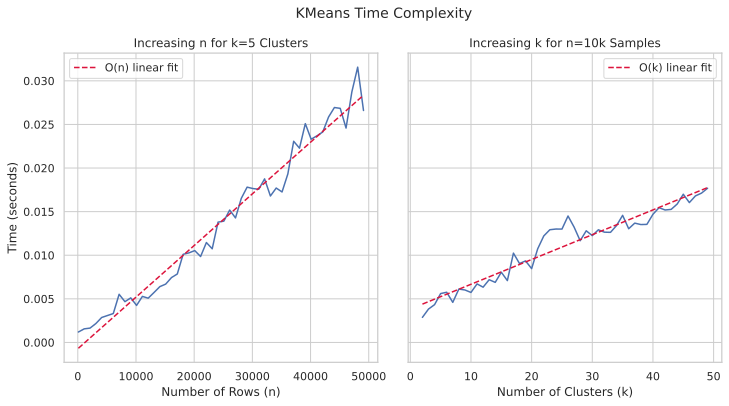

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
fig.tight_layout()
fig.suptitle("KMeans Time Complexity", y=1.08, fontsize=14)

sns.lineplot(x=n_values, y=k5_times, ax=axes[0])
axes[0].set_xlabel("Number of Rows (n)")
axes[0].set_ylabel("Time (seconds)")
axes[0].set_title('Increasing n for k=5 Clusters')

sns.lineplot(x=k_values, y=n10k_times, ax=axes[1])
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_title('Increasing k for n=10k Samples');

# Overlay least-squares lines: k-means is roughly O(n * k), so time should
# grow linearly in n (fixed k) and linearly in k (fixed n).
b_n = np.polyfit(n_values, k5_times, 1)
axes[0].plot(n_values, np.polyval(b_n, n_values), "--", color="crimson",
             label="O(n) linear fit")
axes[0].legend()

b_k = np.polyfit(k_values, n10k_times, 1)
axes[1].plot(k_values, np.polyval(b_k, k_values), "--", color="crimson",
             label="O(k) linear fit")
axes[1].legend();

## Bonus

Consider the following algorithm.

- Modify the code to *count* the number of computational steps taken, saved in a global variable `step_count`.
- Illustrate how this metric changes as $n\to\infty$ (consider the "worst case scenario").
- Estimate the time complexity of this algorithm using $O$-notation, and show it in a plot.
    - Refer to Chapter 11 in the Guttag book for more on asymptotic $O$-notation.

*Note: in this exercise, we are counting *steps*, not time.*

In [8]:
def bin_search(n):
    arr = np.arange(n)
    left = 0
    right = n-1

    x = n-1

    while left <= right:
        middle = left + (right - left) // 2

        # check if x is present at mid
        if (arr[middle] == x):
            return middle

        # if x greater, ignore left half
        if (arr[middle] < x):
            left = middle + 1

        # if x is smaller, ignore right half
        else:
            right = middle - 1

    # if we reach here, then element was not present
    return -1

**Interpretation:** For a fixed number of clusters, the runtime grows roughly along a straight line as `n` increases, so k-means is about $O(n)$ in the number of rows. For a fixed `n`, runtime also grows about linearly with `k`, so overall k-means is approximately $O(n \cdot k)$ (times the number of features and iterations, which are fixed here).

### Bonus: counting steps in binary search

`bin_search` (in *apputil.py*) now increments a global `step_count` once per pass of the `while` loop. Searching for `n - 1` is the worst case, because the target is always in the right half until the very last step.

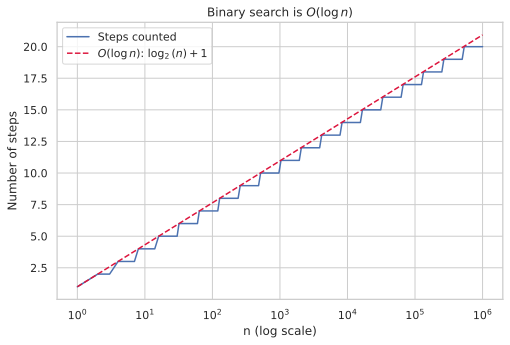

In [9]:
import apputil

bonus_n = np.unique(np.logspace(0, 6, 200).astype(int))
steps = []
for n in bonus_n:
    apputil.bin_search(n)
    steps.append(apputil.step_count)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(bonus_n, steps, label="Steps counted")
ax.plot(bonus_n, np.log2(bonus_n) + 1, "--", color="crimson",
        label=r"$O(\log n)$: $\log_2(n) + 1$")
ax.set_xscale("log")
ax.set_xlabel("n (log scale)")
ax.set_ylabel("Number of steps")
ax.set_title(r"Binary search is $O(\log n)$")
ax.legend();

With `n` on a log-scale axis, the step count climbs as a straight staircase that tracks $\log_2(n) + 1$: doubling `n` adds only one step, because each pass halves the search range. So binary search is $O(\log n)$.